# Libraries

In [1]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Dataset

All variables except G1 (auto-correlated with G2) and G3

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

In [3]:
df = df_raw.copy()
independent_variables = df.columns.to_list()
independent_variables.remove("G1")
independent_variables.remove("G3")
dependent_variable = ["G3"]

# Leaving out outliers

Given the results of Simple Linear Regression, only people who did not perform an exam or with a score lesser or equal to 1 (G1, G2 and G3 results) will be considered outliers, since they did not perform the test or did not even study, altering the dataset.

In [4]:
print("Original shape", df.shape)
df = df.loc[~(df_raw["G1"] <= 1)]
print("After G1", df.shape)
df = df.loc[~(df_raw["G2"] <= 1)]
print("After G2", df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print("After G3", df.shape)

Original shape (649, 42)
After G1 (648, 42)
After G2 (641, 42)
After G3 (632, 42)


A logistic regression will be attempted in order to predict the probability of a student quitting

# Regression

In [5]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.893
Method:                 Least Squares   F-statistic:                     133.0
Date:                Mon, 23 Nov 2026   Prob (F-statistic):          5.58e-267
Time:                        13:01:03   Log-Likelihood:                -786.57
No. Observations:                 632   AIC:                             1655.
Df Residuals:                     591   BIC:                             1838.
Df Model:                          40                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.6476      0.63

# Refined model (only statistically significant variables)

Removing variables

In [6]:
features = model.pvalues[model.pvalues < 0.05].index.tolist()

In [7]:
df = df_raw.copy()
independent_variables = features
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]

In [8]:
print("Original shape", df.shape)
df = df.loc[~(df_raw["G1"] <= 1)]
print("After G1", df.shape)
df = df.loc[~(df_raw["G2"] <= 1)]
print("After G2", df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print("After G3", df.shape)

Original shape (649, 10)
After G1 (648, 10)
After G2 (641, 10)
After G3 (632, 10)


In [9]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.895
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     589.3
Date:                Mon, 23 Nov 2026   Prob (F-statistic):          1.13e-297
Time:                        13:01:35   Log-Likelihood:                -801.93
No. Observations:                 632   AIC:                             1624.
Df Residuals:                     622   BIC:                             1668.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0062      0.527     -0.012      0.9

Again, some variables lose significance

In [11]:
features = model.pvalues[model.pvalues < 0.05].index.tolist()
df = df_raw.copy()
independent_variables = features
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]
print("Original shape", df.shape)
df = df.loc[~(df_raw["G1"] <= 1)]
print("After G1", df.shape)
df = df.loc[~(df_raw["G2"] <= 1)]
print("After G2", df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print("After G3", df.shape)
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

Original shape (649, 6)
After G1 (648, 6)
After G2 (641, 6)
After G3 (632, 6)
                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     1047.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):          2.97e-301
Time:                        13:04:22   Log-Likelihood:                -807.35
No. Observations:                 632   AIC:                             1627.
Df Residuals:                     626   BIC:                             1653.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------

Again, one variable loses significance

In [13]:
features = model.pvalues[model.pvalues < 0.05].index.tolist()
df = df_raw.copy()
independent_variables = features
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]
print("Original shape", df.shape)
df = df.loc[~(df_raw["G1"] <= 1)]
print("After G1", df.shape)
df = df.loc[~(df_raw["G2"] <= 1)]
print("After G2", df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print("After G3", df.shape)
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

Original shape (649, 5)
After G1 (648, 5)
After G2 (641, 5)
After G3 (632, 5)
                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     1303.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):          4.61e-302
Time:                        13:05:38   Log-Likelihood:                -809.16
No. Observations:                 632   AIC:                             1628.
Df Residuals:                     627   BIC:                             1651.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------

In [14]:
std_y = y.std()
std_x = df[independent_variables].std()

beta = model.params[independent_variables] * std_x / std_y

coefficients = pd.DataFrame({
    "B": model.params[independent_variables],
    "Beta": beta,
    "P-value": model.pvalues[independent_variables]
})

print(coefficients.sort_values(
    "Beta",
    key=abs,
    ascending=False
))

                 B      Beta        P-value
G2        0.922634  0.913289  2.672057e-271
failures -0.213746 -0.046585   1.827430e-03
higher   -0.390557 -0.044354   2.108529e-03
age       0.081029  0.036999   8.694133e-03


In [15]:
vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

   Variable         VIF
0     const  225.762493
1       age    1.153591
2  failures    1.293012
3    higher    1.204932
4        G2    1.249097


## Checking assumptions

### Residuals

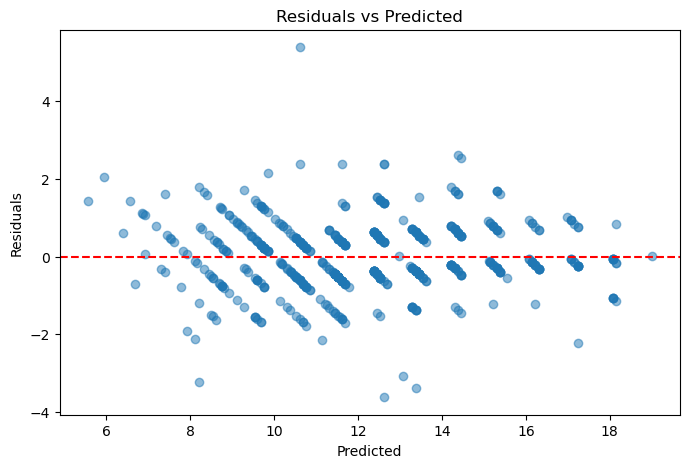

In [16]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

### Independence of errors

In [17]:
dw = durbin_watson(model.resid)

print(f"Durbin-Watson: {dw:.2f}")

Durbin-Watson: 1.81


### Homoscedasticity

In [18]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(10.743097065426955), 'LM p-value': np.float64(0.029608138831722974), 'F Statistic': np.float64(2.710602420755748), 'F p-value': np.float64(0.0293132784784631)}


Data are still heteroscedastic.

With the robust regression, nothing changes

In [19]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     1369.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):          4.15e-308
Time:                        13:06:29   Log-Likelihood:                -809.16
No. Observations:                 632   AIC:                             1628.
Df Residuals:                     627   BIC:                             1651.
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0882      0.528      0.167      0.8

### Normality of residuals

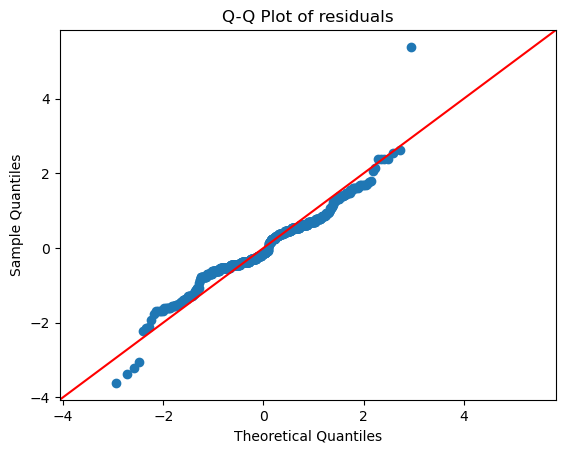

In [20]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [21]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.961149526611221
P-value: 7.046540864054178e-12


Again, the assumption of normality of residuals is violated

# Conclusions

> Model

The `model cannot predict if a student will quit`.\
The model predicts the effects on final grade by:
* age = *older student will have a higher score (almost 0.1 points/year increase)*
* failures = *students who failed previously will have lower scores (almost 0.2 points)*
* higher = *student who want to take higher education will perform better (almost 0.4 points)*
* G2 = *second period grade is the foundation of the final grade (more than 90% of final grade)*

The comparison with the simple linear regression shows very little differences in all parameters.\
The main difference can be resumed as:
* in the simple model the final grade is the previous grade + 1
* in the complete model, the intercept is null (not statistically significant), and the variations are caused by age, previous failures and will to take higher education

## RMSE and MAE

In [22]:
y_pred = model.predict(X)

mae_in = mean_absolute_error(y, y_pred)
rmse_in = np.sqrt(mean_squared_error(y, y_pred))

print("MAE in-sample:", round(mae_in, 3))
print("RMSE in-sample:", round(rmse_in, 3))

MAE in-sample: 0.681
RMSE in-sample: 0.871


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_train = sm.OLS(y_train, X_train).fit()

y_pred_test = model_train.predict(X_test)

mae_out = mean_absolute_error(y_test, y_pred_test)
rmse_out = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("MAE out-of-sample:", round(mae_out, 3))
print("RMSE out-of-sample:", round(rmse_out, 3))

MAE out-of-sample: 0.68
RMSE out-of-sample: 0.902


In [24]:
results = pd.DataFrame({
    'MAE': [mae_in, mae_out],
    'RMSE': [rmse_in, rmse_out]
}, index=['In-sample', 'Out-of-sample'])

display(round(results, 3))

,MAE,RMSE
In-sample,0.681,0.871
Out-of-sample,0.680,0.902


For the ratio between in-sample and out-of-sample.

$\delta$% = $\frac{OOS - IS}{IS} * 100$

where OOS = Out-of-sample, IS = In-sample

| $\delta$%        | Indicative interpretation       |
|------------------|---------------------------------|
| 0 - 5            | Optimal stability               |
| 5 - 10           | Good stability                  |
| 10 - 20          | Possible overfitting            |
| 20 - 30          | Likely overfitting              |
| > 30             | Significant overfitting         |

| Ratio RMSE / MAE | Indicative interpretation       |
|------------------|---------------------------------|
| 1.00 - 1.10      | Homogeneous errors              |
| 1.10 - 1.25      | Possible large errors           |
| 1.25 - 1.50      | Some large errors               |
| 1.50 - 2.00      | Very large errors               |
| > 2              | Large influence of large errors |

In [25]:
print("delta MAE:",
      round((mae_out - mae_in) / mae_in * 100, 2)
)
print("delta RMSE:",
      round((rmse_out - rmse_in) / rmse_in * 100, 2)
)

print("Ratio RMSE/MAE in-sample:",
      round(rmse_in / mae_in, 2)
)

print("Ratio RMSE/MAE out-of-sample:",
      round(rmse_out / mae_out, 2)
)

delta MAE: -0.14
delta RMSE: 3.56
Ratio RMSE/MAE in-sample: 1.28
Ratio RMSE/MAE out-of-sample: 1.33


Optimal stability but some large errors

To check large errors

MAE: 0.6798767985593882
90° percentile: 1.3729473174442042
95° percentile: 1.556790048632908
Max error: 5.382336891701009


<Axes: ylabel='Count'>

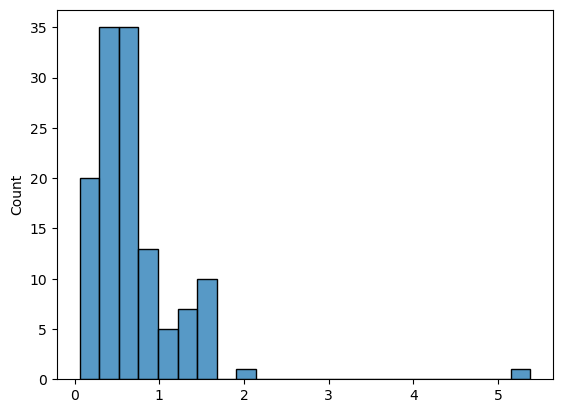

In [26]:
errors = np.abs(y_test - y_pred_test)

print("MAE:", errors.mean())
print("90° percentile:", np.percentile(errors, 90))
print("95° percentile:", np.percentile(errors, 95))
print("Max error:", errors.max())
sns.histplot(errors)